# 🌿 Détection et Classification Automatique de Maladies des Plantes
## Dataset : PlantVillage — 4 Classes Tomate

| Classe | Label |
|--------|-------|
| Tomato_healthy | 0 |
| Tomato_Early_blight | 1 |
| Tomato_Late_blight | 2 |
| Tomato_Bacterial_spot | 3 |

**Pipeline :** Prétraitement → Segmentation → Extraction features → ML (RF / SVM / KNN) → Deep Learning (CNN)

---

##  ÉTAPE 1 — Imports & Configuration

In [6]:
import os
import random
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import cv2
from PIL import Image
from pathlib import Path

# Scikit-image
from skimage.feature import graycomatrix, graycoprops
from skimage.filters import sobel
from skimage import color, exposure

# Scikit-learn
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

print(' Imports réussis')

# ─── Configuration ───────────────────────────────────────────────
IMG_SIZE    = (128, 128)   # Taille de redimensionnement
N_SAMPLES   = 200          # Nb d'images par classe (pour rapidité)
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

# 4 classes choisies
CLASSES = [
    'Tomato_healthy',
    'Tomato_Early_blight',
    'Tomato_Late_blight',
    'Tomato_Bacterial_spot'
]

CLASS_NAMES = ['Healthy', 'Early Blight', 'Late Blight', 'Bacterial Spot']
COLORS = ['#2ecc71', '#e67e22', '#e74c3c', '#9b59b6']

print(f' Classes sélectionnées : {CLASS_NAMES}')
print(f'  Taille images : {IMG_SIZE} | Samples/classe : {N_SAMPLES}')

 Imports réussis
 Classes sélectionnées : ['Healthy', 'Early Blight', 'Late Blight', 'Bacterial Spot']
  Taille images : (128, 128) | Samples/classe : 200


---

##  ÉTAPE 2 — Chargement du Dataset


In [ ]:

DATA_ROOT = Path('')   

def load_images(data_root, classes, n_samples=200, img_size=(128, 128)):
    """Charge les images depuis les dossiers et retourne images + labels."""
    images, labels, paths_list = [], [], []

    for label_idx, class_folder in enumerate(classes):
        folder = data_root / class_folder
        if not folder.exists():
            print(f'  Dossier introuvable : {folder}')
            continue

        all_paths = list(folder.glob('*.jpg')) + list(folder.glob('*.JPG')) + list(folder.glob('*.png'))
        selected  = random.sample(all_paths, min(n_samples, len(all_paths)))

        for p in selected:
            img = cv2.imread(str(p))
            if img is None:
                continue
            img = cv2.resize(img, img_size)
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            images.append(img)
            labels.append(label_idx)
            paths_list.append(str(p))

        print(f'   {CLASS_NAMES[label_idx]:20s} → {len(selected)} images chargées')

    return np.array(images), np.array(labels), paths_list

print(' Chargement des images...')
images, labels, img_paths = load_images(DATA_ROOT, CLASSES, N_SAMPLES, IMG_SIZE)
print(f'\n Total chargé : {len(images)} images | Shape : {images.shape}')
print(f'  Distribution : {dict(zip(CLASS_NAMES, np.bincount(labels)))}')

 Chargement des images...
   Healthy              → 200 images chargées
   Early Blight         → 200 images chargées
   Late Blight          → 200 images chargées
   Bacterial Spot       → 200 images chargées

 Total chargé : 800 images | Shape : (800, 128, 128, 3)
  Distribution : {'Healthy': np.int64(200), 'Early Blight': np.int64(200), 'Late Blight': np.int64(200), 'Bacterial Spot': np.int64(200)}


---

##  ÉTAPE 3 — Visualisation des images brutes

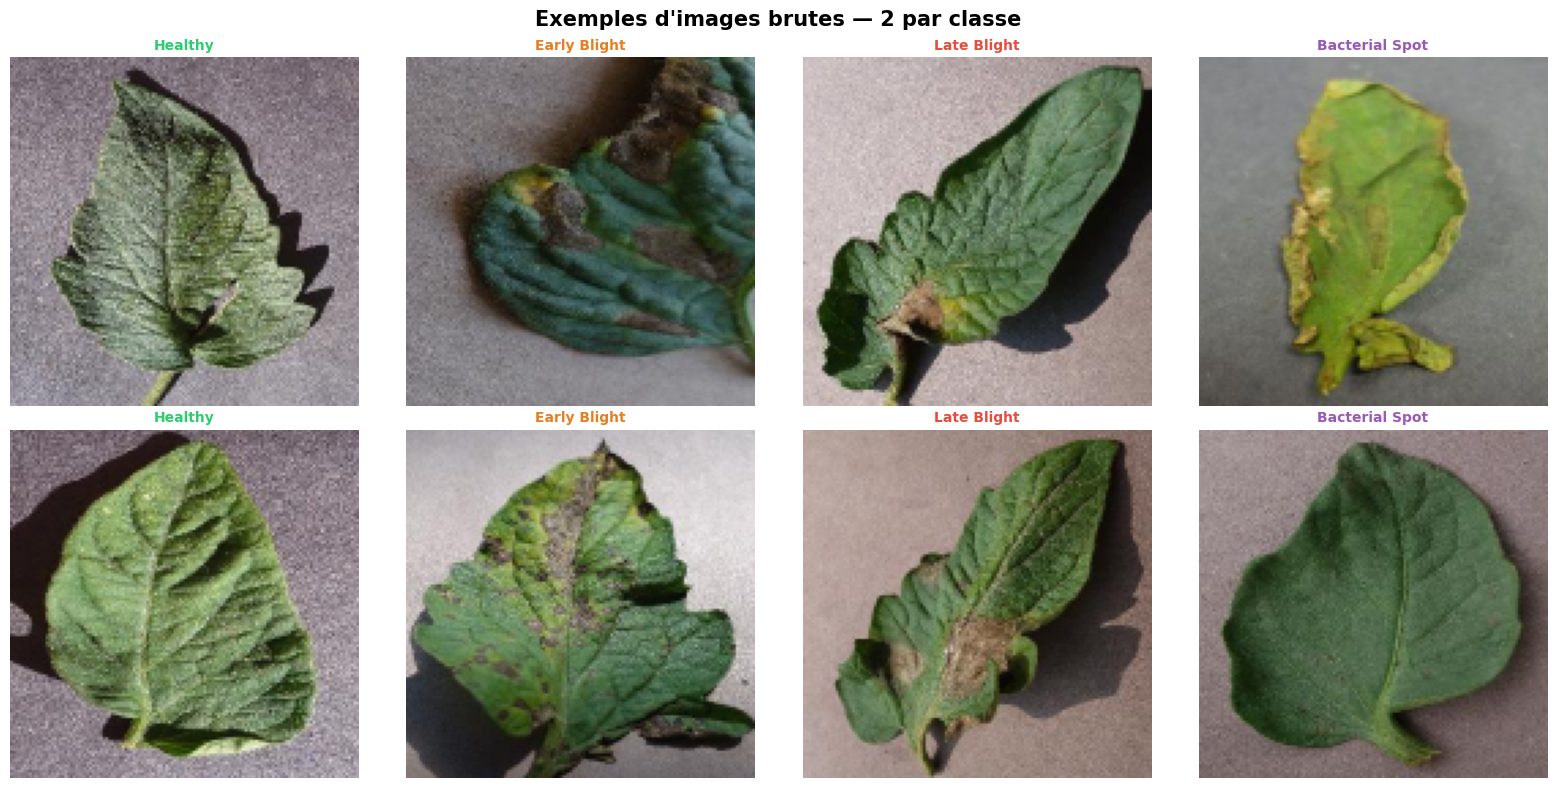

 Figure sauvegardée


In [8]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
fig.suptitle('Exemples d\'images brutes — 2 par classe', fontsize=15, fontweight='bold')

for col, (cls_name, color_hex) in enumerate(zip(CLASS_NAMES, COLORS)):
    idx_list = np.where(labels == col)[0]
    for row in range(2):
        idx = random.choice(idx_list)
        axes[row, col].imshow(images[idx])
        axes[row, col].set_title(cls_name, color=color_hex, fontweight='bold', fontsize=10)
        axes[row, col].axis('off')
        for spine in axes[row, col].spines.values():
            spine.set_edgecolor(color_hex)
            spine.set_linewidth(3)

plt.tight_layout()
plt.savefig('outputs/01_images_brutes.png', dpi=150, bbox_inches='tight')
plt.show()
print(' Figure sauvegardée')

---

##  ÉTAPE 4 — Prétraitement des images

### 4.1 — Redimensionnement (déjà fait au chargement : 128×128)
### 4.2 — Conversion RGB → HSV & Grayscale
### 4.3 — Filtrage du bruit (filtre Gaussien)
### 4.4 — Analyse des histogrammes

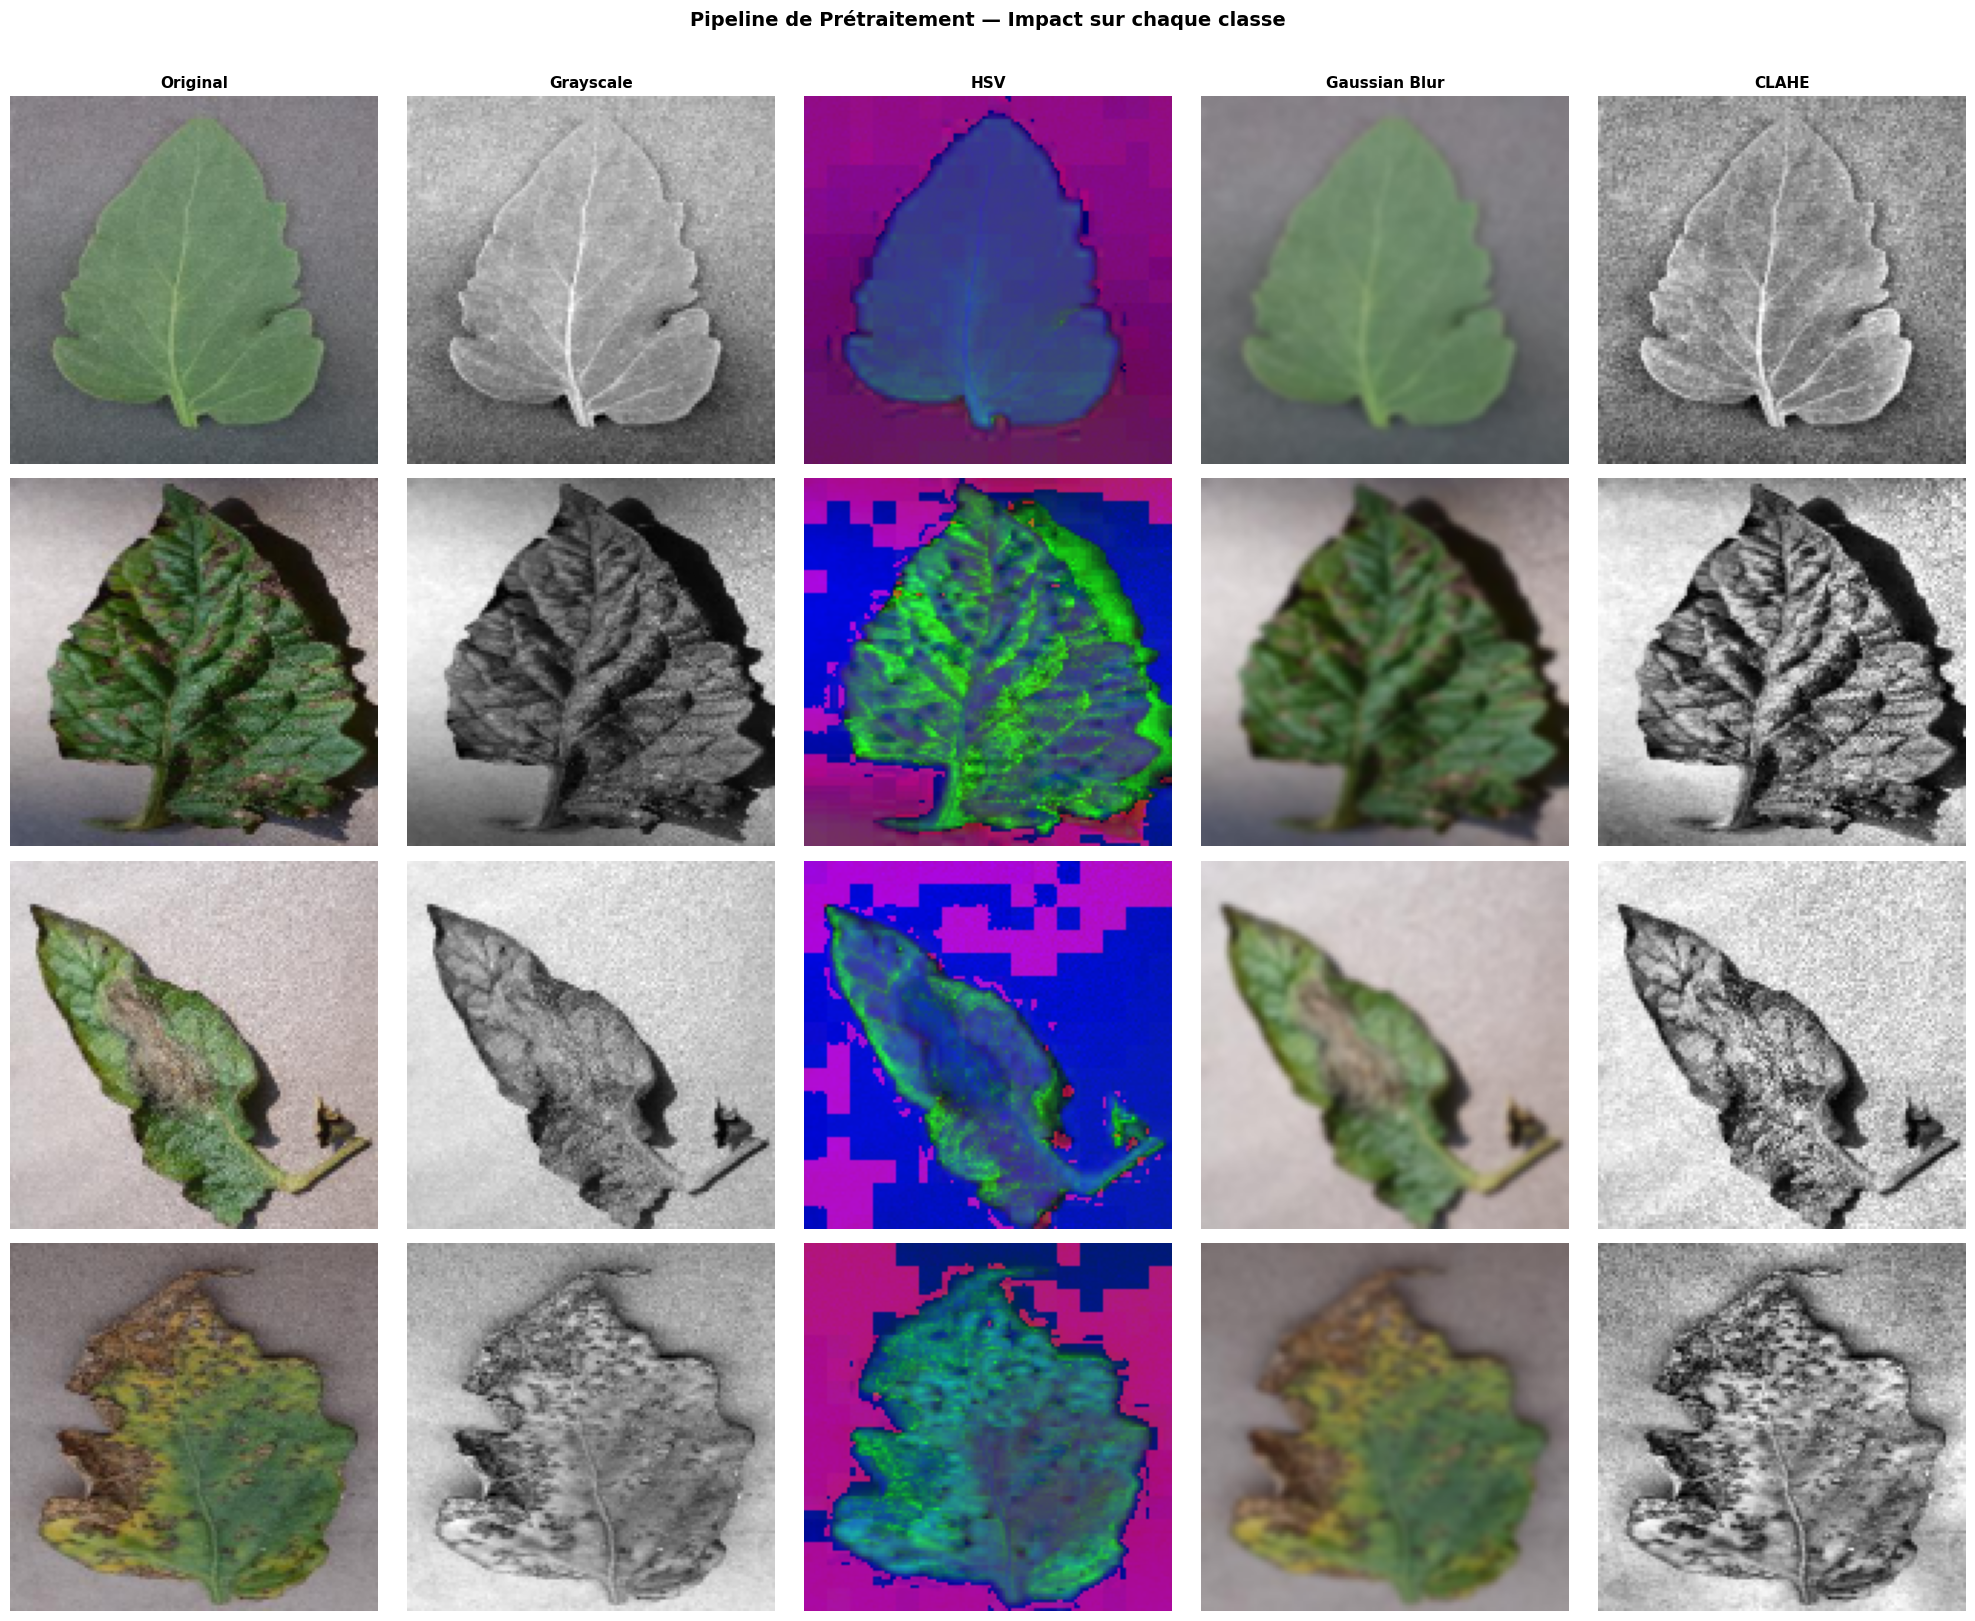

In [9]:
def preprocess_image(img_rgb):
    """
    Applique le pipeline de prétraitement complet.
    Retourne un dict avec toutes les versions de l'image.
    """
    # 1. Grayscale
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)

    # 2. Conversion HSV
    hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)

    # 3. Filtrage Gaussien (réduction bruit)
    blurred = cv2.GaussianBlur(img_rgb, (5, 5), 0)

    # 4. Egalisation d'histogramme sur grayscale (CLAHE)
    clahe  = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    eq_gray = clahe.apply(gray)

    return {
        'original': img_rgb,
        'gray':     gray,
        'hsv':      hsv,
        'blurred':  blurred,
        'eq_gray':  eq_gray
    }

# ─── Visualisation prétraitement sur 1 image de chaque classe ────
fig, axes = plt.subplots(4, 5, figsize=(20, 16))
col_labels = ['Original', 'Grayscale', 'HSV', 'Gaussian Blur', 'CLAHE']

for row, (cls_idx, cls_name) in enumerate(zip(range(4), CLASS_NAMES)):
    sample_idx = np.where(labels == cls_idx)[0][0]
    sample     = images[sample_idx]
    pp         = preprocess_image(sample)

    versions = [pp['original'], pp['gray'], pp['hsv'], pp['blurred'], pp['eq_gray']]
    cmaps    = [None, 'gray', None, None, 'gray']

    for col, (version, cmap, title) in enumerate(zip(versions, cmaps, col_labels)):
        axes[row, col].imshow(version, cmap=cmap)
        if row == 0:
            axes[row, col].set_title(title, fontsize=11, fontweight='bold')
        if col == 0:
            axes[row, col].set_ylabel(cls_name, fontsize=10, color=COLORS[row], fontweight='bold')
        axes[row, col].axis('off')

fig.suptitle('Pipeline de Prétraitement — Impact sur chaque classe', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('outputs/02_pretraitement.png', dpi=150, bbox_inches='tight')
plt.show()

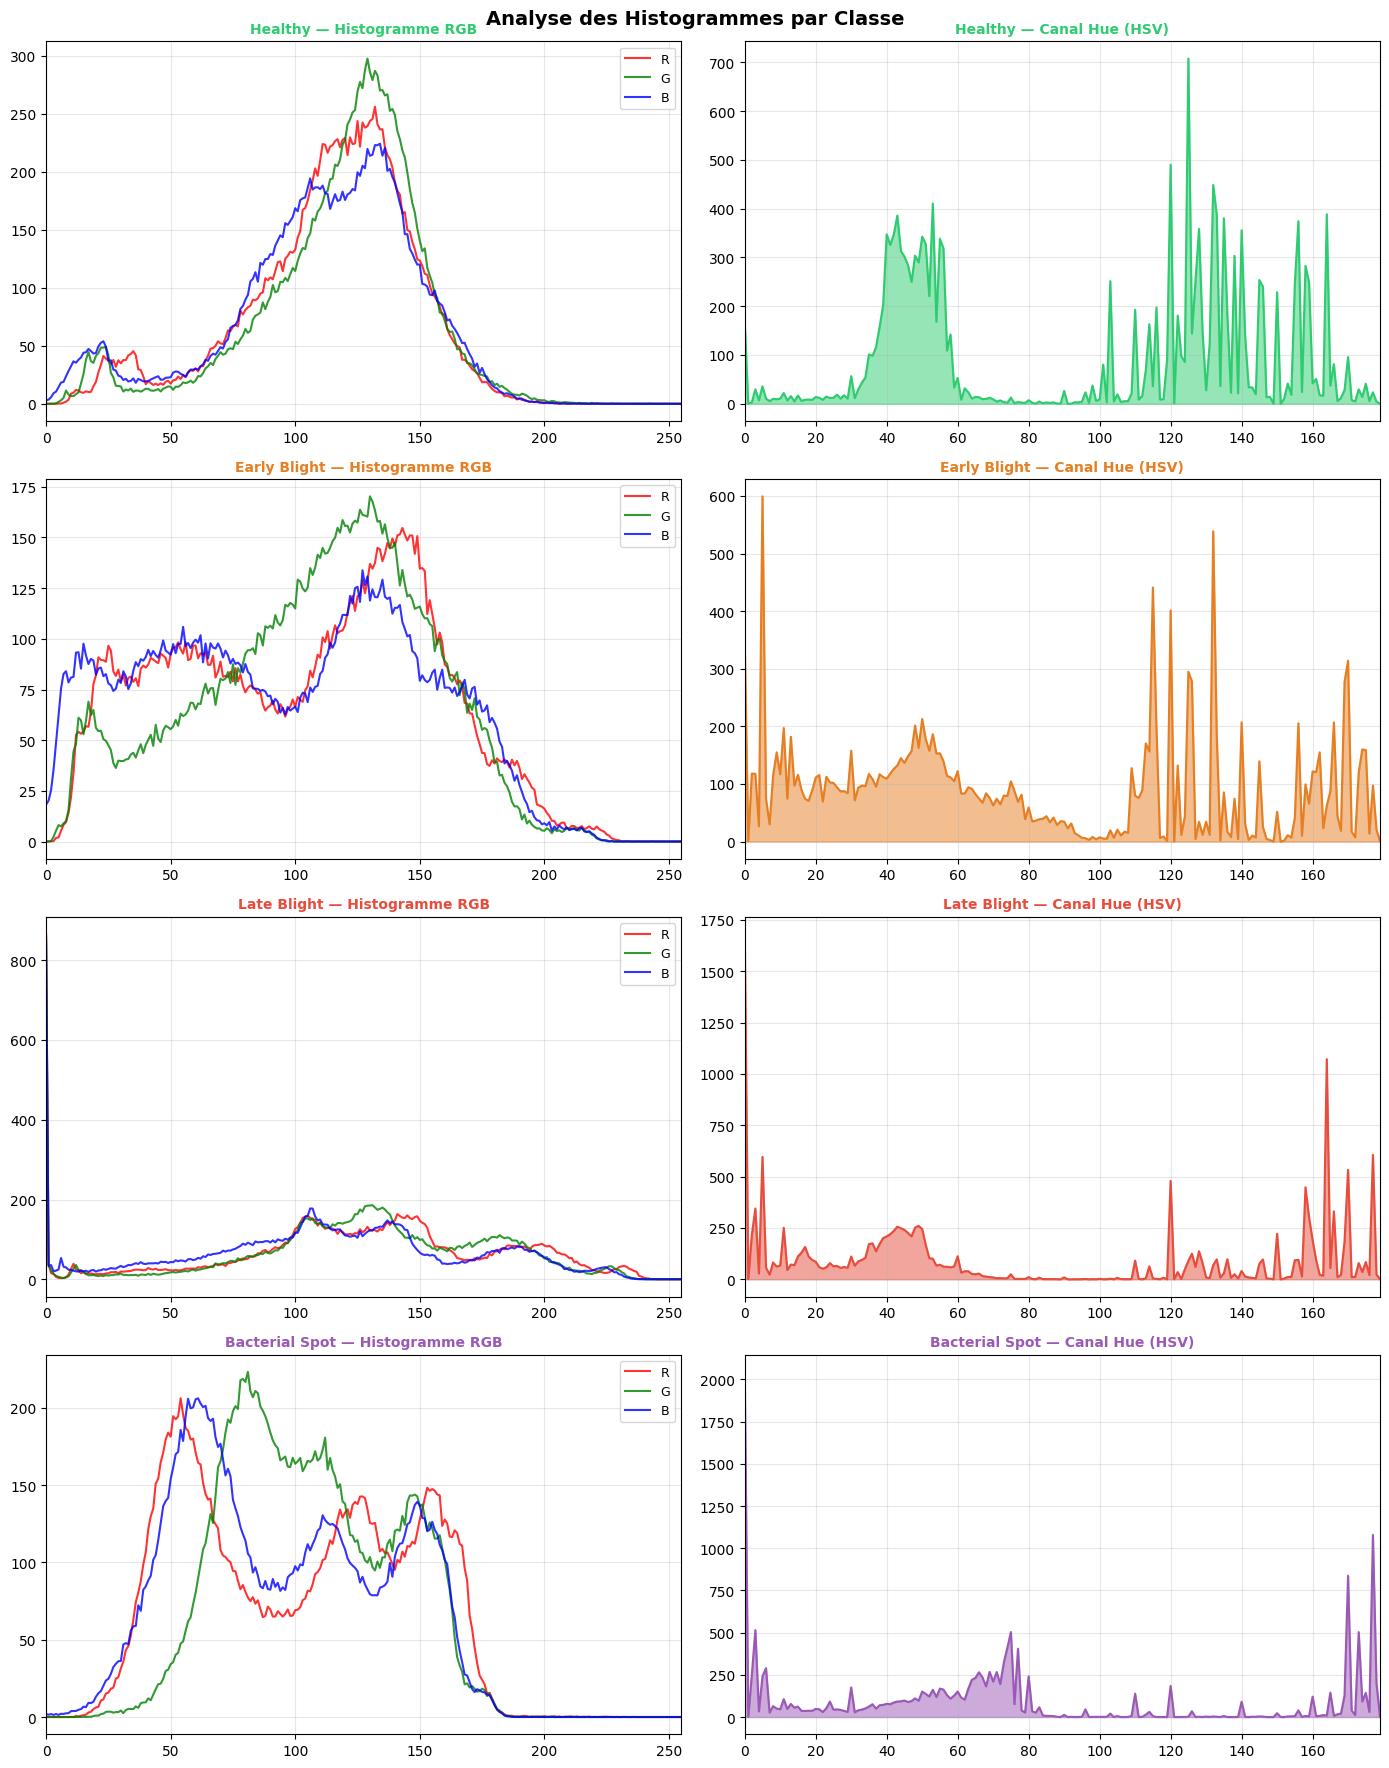


 Description : Les histogrammes RGB montrent la distribution des intensités.
    Le canal Hue (HSV) est très utile pour distinguer les maladies (zones brunes/jaunes).


In [10]:
# ─── Analyse des histogrammes RGB et HSV ─────────────────────────
fig, axes = plt.subplots(4, 2, figsize=(14, 18))
fig.suptitle('Analyse des Histogrammes par Classe', fontsize=14, fontweight='bold')

for row, (cls_idx, cls_name, clr) in enumerate(zip(range(4), CLASS_NAMES, COLORS)):
    # Prendre 10 images par classe pour moyenner
    class_imgs = images[labels == cls_idx][:10]

    # Histogramme RGB moyen
    ax_rgb = axes[row, 0]
    for ch, ch_name, ch_color in zip([0,1,2], ['R','G','B'], ['red','green','blue']):
        hist = np.mean([cv2.calcHist([img], [ch], None, [256], [0,256]).flatten()
                        for img in class_imgs], axis=0)
        ax_rgb.plot(hist, color=ch_color, alpha=0.8, linewidth=1.5, label=ch_name)
    ax_rgb.set_title(f'{cls_name} — Histogramme RGB', fontsize=10, color=clr, fontweight='bold')
    ax_rgb.legend(fontsize=9)
    ax_rgb.set_xlim([0,255])
    ax_rgb.grid(alpha=0.3)

    # Histogramme Canal H (Hue) de HSV
    ax_hsv = axes[row, 1]
    hue_hist = np.mean([
        cv2.calcHist([cv2.cvtColor(img, cv2.COLOR_RGB2HSV)], [0], None, [180], [0,180]).flatten()
        for img in class_imgs], axis=0)
    ax_hsv.fill_between(range(180), hue_hist, alpha=0.5, color=clr)
    ax_hsv.plot(hue_hist, color=clr, linewidth=1.5)
    ax_hsv.set_title(f'{cls_name} — Canal Hue (HSV)', fontsize=10, color=clr, fontweight='bold')
    ax_hsv.set_xlim([0,179])
    ax_hsv.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('outputs/03_histogrammes.png', dpi=150, bbox_inches='tight')
plt.show()
print('\n Description : Les histogrammes RGB montrent la distribution des intensités.')
print('    Le canal Hue (HSV) est très utile pour distinguer les maladies (zones brunes/jaunes).')

---

##  ÉTAPE 5 — Segmentation & Détection de Contours

### 5.1 — Détection de contours : Sobel & Canny
### 5.2 — Segmentation : Seuillage (Otsu) & Segmentation couleur HSV

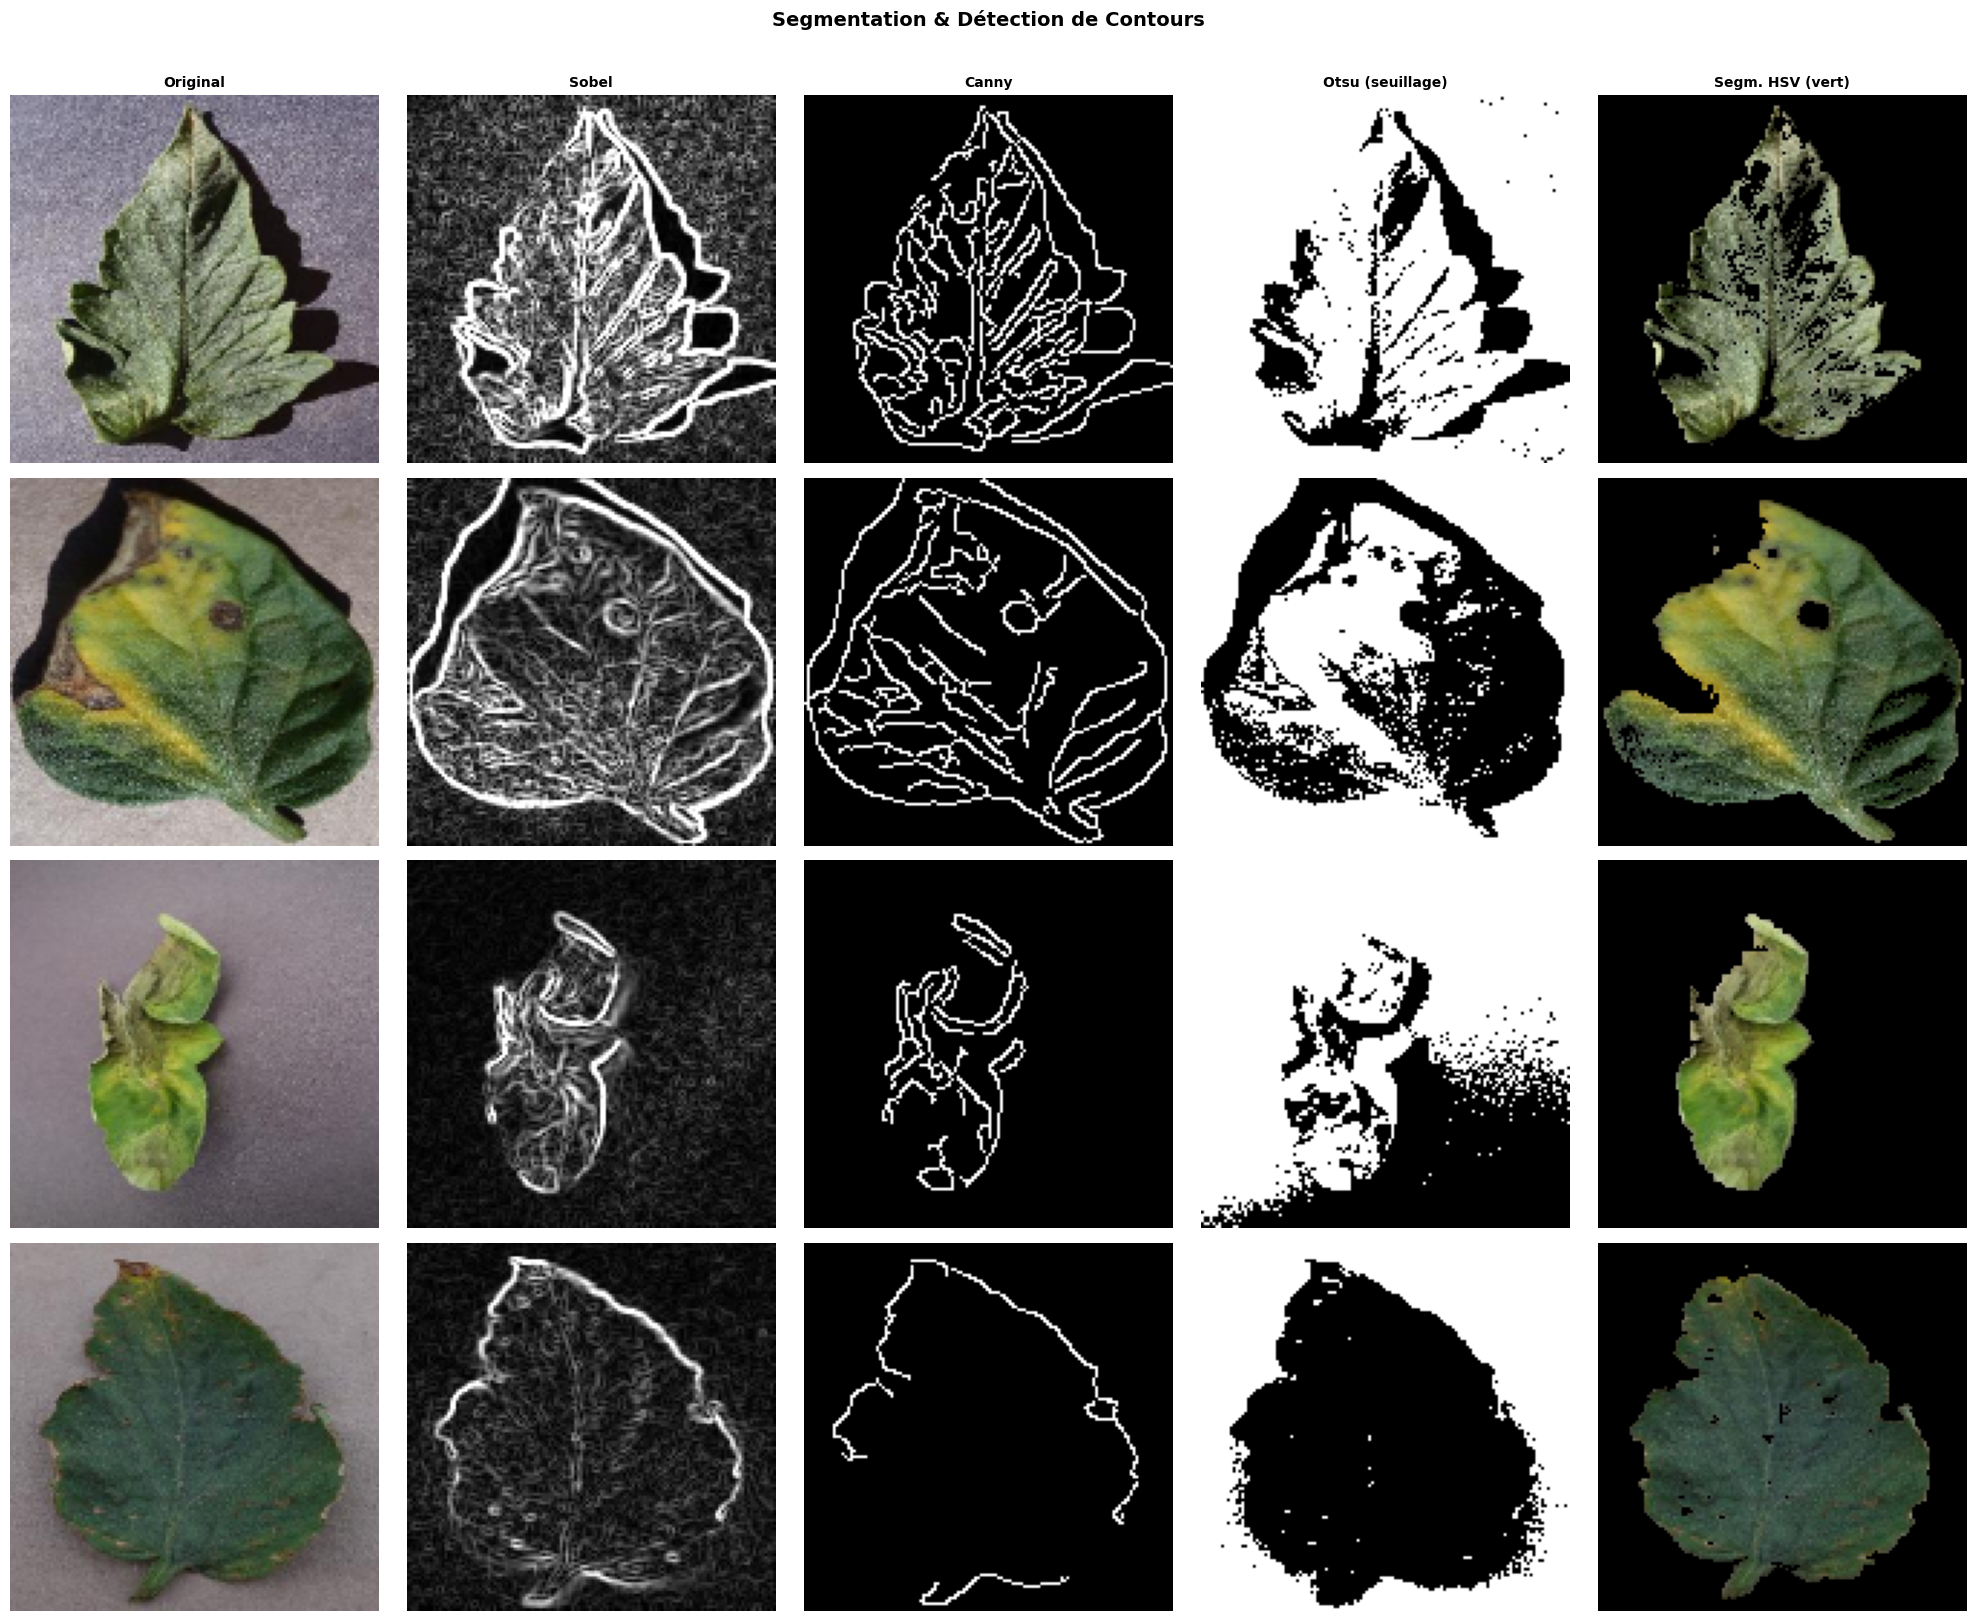

In [11]:
def segment_image(img_rgb):
    """Applique différentes méthodes de segmentation."""
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)

    # Contours Sobel
    sobel_x  = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
    sobel_y  = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
    sobel_img = np.uint8(np.clip(np.sqrt(sobel_x**2 + sobel_y**2), 0, 255))

    # Contours Canny
    blurred   = cv2.GaussianBlur(gray, (5, 5), 0)
    canny_img = cv2.Canny(blurred, 50, 150)

    # Seuillage Otsu
    _, otsu = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    # Segmentation couleur HSV (isoler feuille verte)
    hsv    = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)
    lower  = np.array([25, 40, 40])   # vert clair
    upper  = np.array([90, 255, 255]) # vert foncé
    mask_g = cv2.inRange(hsv, lower, upper)
    seg_hsv = cv2.bitwise_and(img_rgb, img_rgb, mask=mask_g)

    return {
        'original': img_rgb,
        'sobel':    sobel_img,
        'canny':    canny_img,
        'otsu':     otsu,
        'hsv_seg':  seg_hsv
    }

# Visualisation
fig, axes = plt.subplots(4, 5, figsize=(20, 16))
seg_labels = ['Original', 'Sobel', 'Canny', 'Otsu (seuillage)', 'Segm. HSV (vert)']

for row, (cls_idx, cls_name, clr) in enumerate(zip(range(4), CLASS_NAMES, COLORS)):
    sample = images[np.where(labels == cls_idx)[0][2]]
    seg    = segment_image(sample)
    versions = [seg['original'], seg['sobel'], seg['canny'], seg['otsu'], seg['hsv_seg']]
    cmaps    = [None, 'gray', 'gray', 'gray', None]

    for col, (version, cmap, title) in enumerate(zip(versions, cmaps, seg_labels)):
        axes[row, col].imshow(version, cmap=cmap)
        if row == 0:
            axes[row, col].set_title(title, fontsize=10, fontweight='bold')
        if col == 0:
            axes[row, col].set_ylabel(cls_name, fontsize=9, color=clr, fontweight='bold')
        axes[row, col].axis('off')

fig.suptitle('Segmentation & Détection de Contours', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('outputs/04_segmentation.png', dpi=150, bbox_inches='tight')
plt.show()

---

##  ÉTAPE 6 — Extraction de Caractéristiques (Feature Engineering)

On calcule pour chaque image un **vecteur de features** composé de :
- **Couleur** : Histogrammes RGB + HSV (64 bins × 6 canaux = 384 features)
- **Texture** : GLCM — contraste, dissimilarité, homogénéité, énergie, corrélation
- **Forme** : Surface de la feuille, périmètre, circularité

In [12]:
def extract_color_features(img_rgb, n_bins=32):
    """Histogrammes RGB et HSV normalisés."""
    feats = []
    # RGB
    for ch in range(3):
        hist = cv2.calcHist([img_rgb], [ch], None, [n_bins], [0, 256]).flatten()
        feats.extend(hist / hist.sum())
    # HSV
    hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)
    for ch in range(3):
        maxval = 180 if ch == 0 else 256
        hist   = cv2.calcHist([hsv], [ch], None, [n_bins], [0, maxval]).flatten()
        feats.extend(hist / (hist.sum() + 1e-6))
    return np.array(feats)

def extract_texture_features(img_rgb):
    """Features de texture via GLCM."""
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    # Normaliser en 0-255 uint8
    if gray.max() > 0:
        gray = (gray / gray.max() * 255).astype(np.uint8)

    glcm = graycomatrix(gray, distances=[1, 3], angles=[0, np.pi/4, np.pi/2],
                        levels=256, symmetric=True, normed=True)

    props = ['contrast', 'dissimilarity', 'homogeneity', 'energy', 'correlation']
    feats = []
    for prop in props:
        val = graycoprops(glcm, prop)
        feats.extend([val.mean(), val.std()])
    return np.array(feats)

def extract_shape_features(img_rgb):
    """Surface, périmètre, circularité de la feuille."""
    hsv   = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)
    mask  = cv2.inRange(hsv, np.array([20, 30, 30]), np.array([90, 255, 255]))
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    if not contours:
        return np.array([0.0, 0.0, 0.0, 0.0])

    cnt  = max(contours, key=cv2.contourArea)
    area = cv2.contourArea(cnt)
    perim = cv2.arcLength(cnt, True)
    circ  = (4 * np.pi * area / (perim ** 2)) if perim > 0 else 0
    total_pixels = img_rgb.shape[0] * img_rgb.shape[1]
    coverage = area / total_pixels

    return np.array([area, perim, circ, coverage])

def extract_all_features(img_rgb):
    """Concatene tous les vecteurs de features."""
    color   = extract_color_features(img_rgb)
    texture = extract_texture_features(img_rgb)
    shape   = extract_shape_features(img_rgb)
    return np.concatenate([color, texture, shape])

print(' Extraction des features en cours...')
feature_matrix = []
for i, img in enumerate(images):
    feature_matrix.append(extract_all_features(img))
    if (i + 1) % 100 == 0:
        print(f'  Traitement : {i+1}/{len(images)} images')

X = np.array(feature_matrix)
y = labels

print(f'\n Features extraites : {X.shape[1]} features par image')
print(f'   → Couleur (RGB+HSV) : {32*6} features')
print(f'   → Texture (GLCM)    : 10 features')
print(f'   → Forme             : 4 features')

 Extraction des features en cours...
  Traitement : 100/800 images
  Traitement : 200/800 images
  Traitement : 300/800 images
  Traitement : 400/800 images
  Traitement : 500/800 images
  Traitement : 600/800 images
  Traitement : 700/800 images
  Traitement : 800/800 images

 Features extraites : 206 features par image
   → Couleur (RGB+HSV) : 192 features
   → Texture (GLCM)    : 10 features
   → Forme             : 4 features


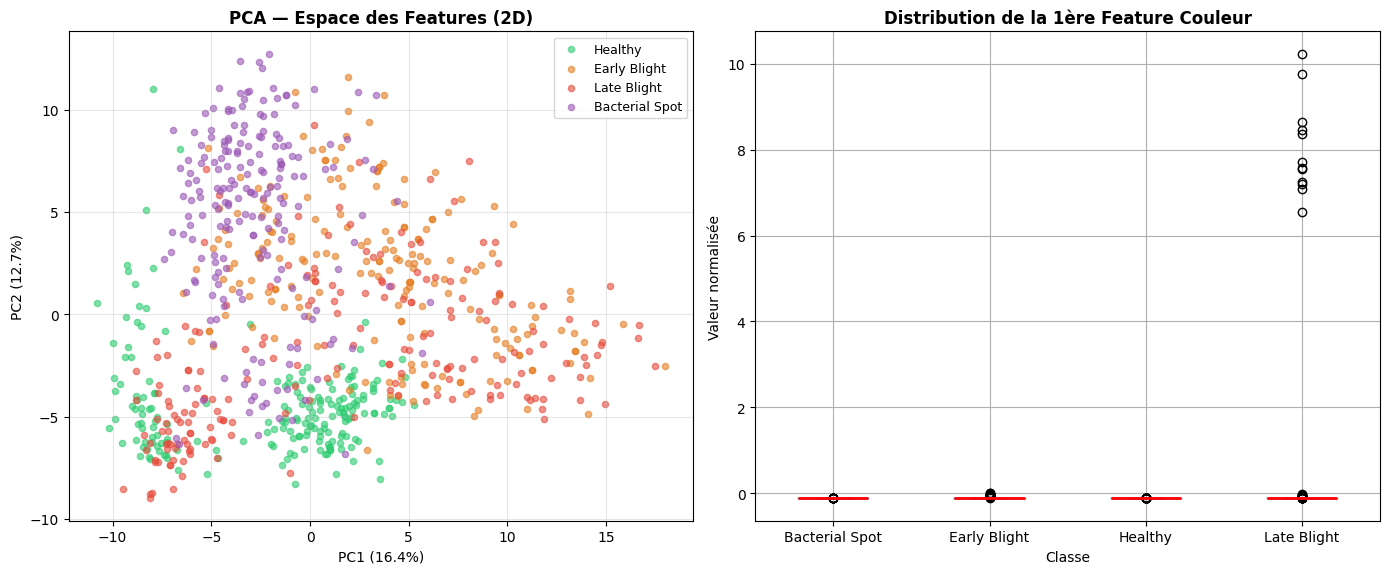

In [13]:
# ─── Visualisation importance des features (corrélation avec label) ───
from sklearn.decomposition import PCA

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=2, random_state=RANDOM_SEED)
X_pca = pca.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# PCA scatter
for cls_idx, (cls_name, clr) in enumerate(zip(CLASS_NAMES, COLORS)):
    mask_c = y == cls_idx
    axes[0].scatter(X_pca[mask_c, 0], X_pca[mask_c, 1],
                    label=cls_name, color=clr, alpha=0.6, s=20)
axes[0].set_title('PCA — Espace des Features (2D)', fontweight='bold')
axes[0].legend(fontsize=9)
axes[0].grid(alpha=0.3)
axes[0].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
axes[0].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')

# Distribution des features par classe (boxplot sur 1 feature couleur)
df_viz = pd.DataFrame({'Feature_0': X_scaled[:, 0], 'Classe': [CLASS_NAMES[l] for l in y]})
df_viz.boxplot(column='Feature_0', by='Classe', ax=axes[1],
               boxprops=dict(color='steelblue'), medianprops=dict(color='red', linewidth=2))
axes[1].set_title('Distribution de la 1ère Feature Couleur', fontweight='bold')
axes[1].set_xlabel('Classe')
axes[1].set_ylabel('Valeur normalisée')
plt.suptitle('')

plt.tight_layout()
plt.savefig('outputs/05_features.png', dpi=150, bbox_inches='tight')
plt.show()

---

##  ÉTAPE 7 — Classification Machine Learning
### Random Forest | SVM | KNN — Comparaison complète

In [14]:
# ─── Split Train / Test + Normalisation (CORRIGÉ) ─────────────────
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
# 1. Split AVANT toute transformation
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_SEED,
    stratify=y
)

# 2. Normalisation (fit uniquement sur train)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test  = scaler.transform(X_test)

# 3. Vérifications
print(f' Train : {X_train.shape[0]} | Test : {X_test.shape[0]}')
print(f'   Distribution train : {dict(zip(CLASS_NAMES, np.bincount(y_train)))}')
print(f'   Distribution test  : {dict(zip(CLASS_NAMES, np.bincount(y_test)))}')

 Train : 640 | Test : 160
   Distribution train : {'Healthy': np.int64(160), 'Early Blight': np.int64(160), 'Late Blight': np.int64(160), 'Bacterial Spot': np.int64(160)}
   Distribution test  : {'Healthy': np.int64(40), 'Early Blight': np.int64(40), 'Late Blight': np.int64(40), 'Bacterial Spot': np.int64(40)}


In [15]:
from sklearn.model_selection import GridSearchCV
import time

# ─── Définition des modèles ───────────────────────────────────────
models = {
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=RANDOM_SEED, n_jobs=-1),
    'SVM': SVC(kernel='rbf', C=10, gamma='scale', random_state=RANDOM_SEED, probability=True),
    'KNN':           KNeighborsClassifier(n_neighbors=7, metric='euclidean')
}

results = {}

for name, model in models.items():
    print(f'\n Entraînement : {name}...')
    t0 = time.time()
    model.fit(X_train, y_train)
    train_time = time.time() - t0

    y_pred = model.predict(X_test)

    acc  = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='macro', zero_division=0)
    rec  = recall_score(y_test, y_pred, average='macro', zero_division=0)
    f1   = f1_score(y_test, y_pred, average='macro', zero_division=0)

    # Cross-validation 5 folds
    cv_scores = cross_val_score(model, X_scaled, y, cv=5, scoring='accuracy', n_jobs=-1)

    results[name] = {
        'model':      model,
        'y_pred':     y_pred,
        'accuracy':   acc,
        'precision':  prec,
        'recall':     rec,
        'f1':         f1,
        'cv_mean':    cv_scores.mean(),
        'cv_std':     cv_scores.std(),
        'train_time': train_time
    }

    print(f'    Accuracy : {acc:.4f} | Precision : {prec:.4f} | Recall : {rec:.4f} | F1 : {f1:.4f}')
    print(f'   CV (5-fold): {cv_scores.mean():.4f} ± {cv_scores.std():.4f} | Temps : {train_time:.2f}s')

print('\n Entraînement terminé pour tous les modèles.')


 Entraînement : Random Forest...
    Accuracy : 0.9000 | Precision : 0.9025 | Recall : 0.9000 | F1 : 0.8994
   CV (5-fold): 0.9288 ± 0.0184 | Temps : 0.20s

 Entraînement : SVM...
    Accuracy : 0.9500 | Precision : 0.9504 | Recall : 0.9500 | F1 : 0.9500
   CV (5-fold): 0.9275 ± 0.0064 | Temps : 0.15s

 Entraînement : KNN...
    Accuracy : 0.8812 | Precision : 0.8910 | Recall : 0.8812 | F1 : 0.8799
   CV (5-fold): 0.8825 ± 0.0191 | Temps : 0.00s

 Entraînement terminé pour tous les modèles.


---

## 📊 ÉTAPE 8 — Évaluation & Comparaison des Modèles

In [16]:
# ─── Tableau récapitulatif ────────────────────────────────────────
summary = pd.DataFrame({
    'Modèle':    list(results.keys()),
    'Accuracy':  [results[m]['accuracy']  for m in results],
    'Precision': [results[m]['precision'] for m in results],
    'Recall':    [results[m]['recall']    for m in results],
    'F1-Score':  [results[m]['f1']        for m in results],
    'CV Mean':   [results[m]['cv_mean']   for m in results],
    'CV Std':    [results[m]['cv_std']    for m in results],
    'Temps (s)': [results[m]['train_time'] for m in results],
}).set_index('Modèle')

print(' Tableau récapitulatif des performances :\n')
print(summary.round(4).to_string())

# Identifier le meilleur modèle
best = summary['Accuracy'].idxmax()
print(f'\n Meilleur modèle : {best} (Accuracy = {summary.loc[best, "Accuracy"]:.4f})')

 Tableau récapitulatif des performances :

               Accuracy  Precision  Recall  F1-Score  CV Mean  CV Std  Temps (s)
Modèle                                                                          
Random Forest    0.9000     0.9025  0.9000    0.8994   0.9288  0.0184     0.2049
SVM              0.9500     0.9504  0.9500    0.9500   0.9275  0.0064     0.1469
KNN              0.8812     0.8910  0.8812    0.8799   0.8825  0.0191     0.0010

 Meilleur modèle : SVM (Accuracy = 0.9500)


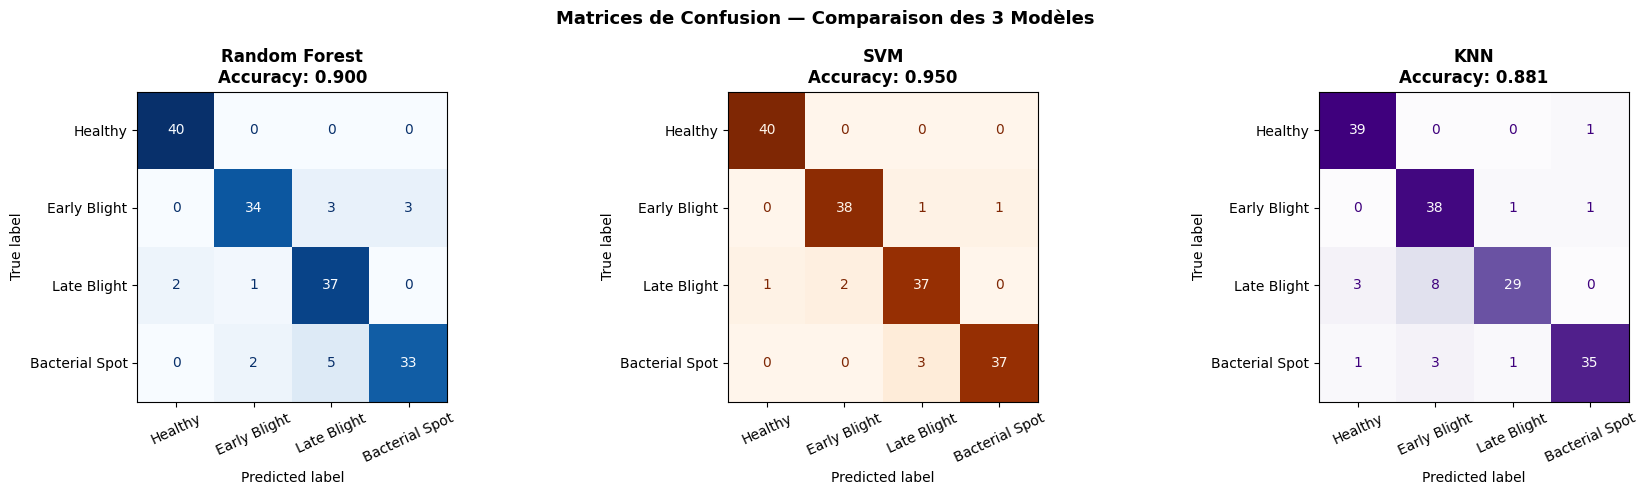

In [17]:
# ─── Matrices de confusion ────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Matrices de Confusion — Comparaison des 3 Modèles', fontsize=13, fontweight='bold')

model_colors = ['Blues', 'Oranges', 'Purples']

for ax, (name, res), cmap in zip(axes, results.items(), model_colors):
    cm = confusion_matrix(y_test, res['y_pred'])
    disp = ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES)
    disp.plot(ax=ax, colorbar=False, cmap=cmap, xticks_rotation=25)
    ax.set_title(f'{name}\nAccuracy: {res["accuracy"]:.3f}', fontweight='bold')

plt.tight_layout()
plt.savefig('outputs/06_confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()

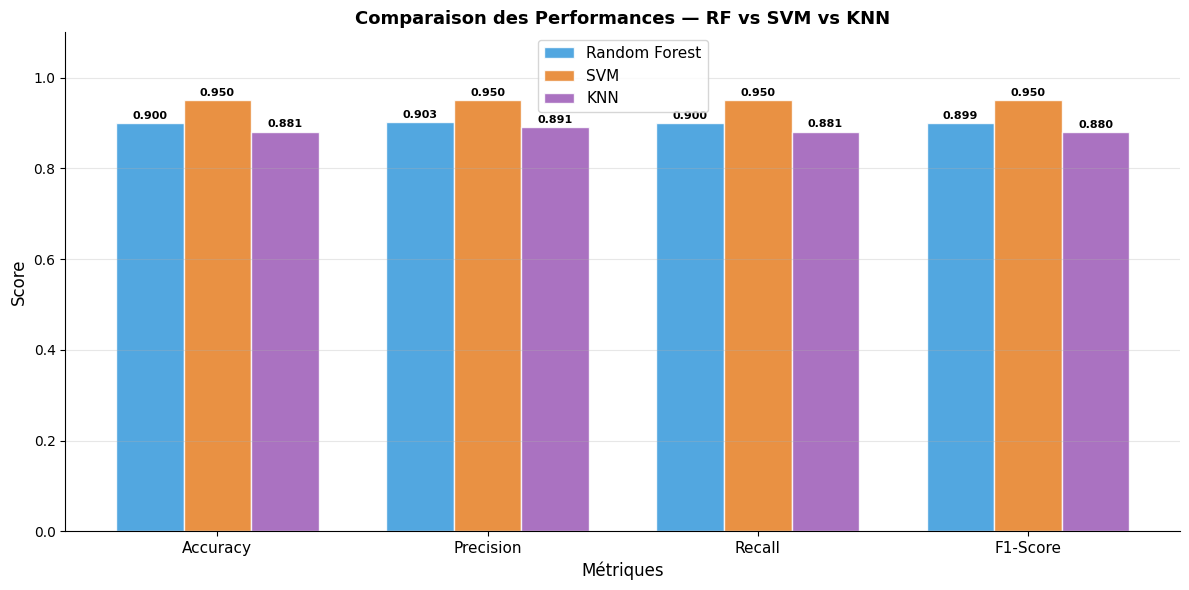

In [18]:
# ─── Graphique comparatif des métriques ──────────────────────────
metrics  = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
x        = np.arange(len(metrics))
width    = 0.25
bar_clrs = ['#3498db', '#e67e22', '#9b59b6']

fig, ax = plt.subplots(figsize=(12, 6))
for i, (name, clr) in enumerate(zip(results.keys(), bar_clrs)):
    vals = [results[name]['accuracy'], results[name]['precision'],
            results[name]['recall'],   results[name]['f1']]
    bars = ax.bar(x + i*width, vals, width, label=name, color=clr, alpha=0.85, edgecolor='white')
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                f'{val:.3f}', ha='center', va='bottom', fontsize=8, fontweight='bold')

ax.set_xlabel('Métriques', fontsize=12)
ax.set_ylabel('Score', fontsize=12)
ax.set_title('Comparaison des Performances — RF vs SVM vs KNN', fontsize=13, fontweight='bold')
ax.set_xticks(x + width)
ax.set_xticklabels(metrics, fontsize=11)
ax.set_ylim(0, 1.1)
ax.legend(fontsize=11)
ax.grid(axis='y', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('outputs/07_comparaison_ML.png', dpi=150, bbox_inches='tight')
plt.show()

In [19]:
# ─── Rapport de classification détaillé du meilleur modèle ───────
best_model_name = summary['Accuracy'].idxmax()
print(f' Meilleur modèle : {best_model_name} (Accuracy = {summary.loc[best_model_name, "Accuracy"]:.4f})')
print('\n Rapport de classification détaillé :\n')
print(classification_report(
    y_test, results[best_model_name]['y_pred'],
    target_names=CLASS_NAMES
))

 Meilleur modèle : SVM (Accuracy = 0.9500)

 Rapport de classification détaillé :

                precision    recall  f1-score   support

       Healthy       0.98      1.00      0.99        40
  Early Blight       0.95      0.95      0.95        40
   Late Blight       0.90      0.93      0.91        40
Bacterial Spot       0.97      0.93      0.95        40

      accuracy                           0.95       160
     macro avg       0.95      0.95      0.95       160
  weighted avg       0.95      0.95      0.95       160



---

##  ÉTAPE 9 — Extension Deep Learning (CNN)

Comparaison avec un CNN simple entraîné from scratch.

In [20]:
# ═══════════════════════════════════════════════════════════════
# ÉTAPE 9 — Deep Learning : Transfer Learning (MobileNetV2)
# Beaucoup plus adapté aux petits datasets que CNN from scratch
# ═══════════════════════════════════════════════════════════════

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.applications import MobileNetV2

print(f'TensorFlow : {tf.__version__}')

# ── 1. Augmenter le nombre de samples (utiliser plus d'images) ──
print('\n Rechargement avec plus d\'images (500/classe)...')
images_dl, labels_dl, _ = load_images(DATA_ROOT, CLASSES, n_samples=500, img_size=IMG_SIZE)
print(f' Dataset DL : {len(images_dl)} images')

# ── 2. Préparation ──────────────────────────────────────────────
X_cnn = images_dl.astype('float32') / 255.0
y_cnn = to_categorical(labels_dl, num_classes=4)

X_tr, X_te, y_tr, y_te = train_test_split(
    X_cnn, y_cnn, test_size=0.2, random_state=RANDOM_SEED, stratify=labels_dl
)
print(f'Train : {X_tr.shape} | Test : {X_te.shape}')

# ── 3. Data Augmentation ────────────────────────────────────────
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip('horizontal_and_vertical'),
    layers.RandomRotation(0.2),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.15),
], name='data_augmentation')

# ── 4. Modèle Transfer Learning (MobileNetV2) ───────────────────
def build_transfer_model(input_shape=(128, 128, 3), num_classes=4):
    # Base pré-entraînée sur ImageNet (sans les couches de classification)
    base_model = MobileNetV2(
        input_shape=input_shape,
        include_top=False,
        weights='imagenet'
    )
    # Geler les couches de la base au début
    base_model.trainable = False

    inputs = tf.keras.Input(shape=input_shape)
    x = data_augmentation(inputs)
    x = tf.keras.applications.mobilenet_v2.preprocess_input(x * 255.0)
    x = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)

    model = tf.keras.Model(inputs, outputs)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model, base_model

cnn_model, base_model = build_transfer_model()
print(f'\n Paramètres entraînables : {sum([tf.size(w).numpy() for w in cnn_model.trainable_weights]):,}')
cnn_model.summary()

TensorFlow : 2.21.0

 Rechargement avec plus d'images (500/classe)...
   Healthy              → 500 images chargées
   Early Blight         → 500 images chargées
   Late Blight          → 500 images chargées
   Bacterial Spot       → 500 images chargées
 Dataset DL : 2000 images
Train : (1600, 128, 128, 3) | Test : (400, 128, 128, 3)

 Paramètres entraînables : 164,484


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ multiply (Multiply)             │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,468 (9.24 MB)

 Trainable params: 164,484 (642.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [21]:
# ── 5. Phase 1 : Entraîner seulement le classifieur (base gelée) ─
BATCH_SIZE = 32

train_ds = tf.data.Dataset.from_tensor_slices((X_tr, y_tr))\
    .shuffle(2000).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
val_ds = tf.data.Dataset.from_tensor_slices((X_te, y_te))\
    .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

cb_early = callbacks.EarlyStopping(monitor='val_accuracy', patience=6,
                                    restore_best_weights=True, verbose=1)
cb_lr    = callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.3,
                                        patience=3, min_lr=1e-7, verbose=1)

print(' Phase 1 — Base gelée (entraînement classifieur)...')
history1 = cnn_model.fit(
    train_ds, epochs=20, validation_data=val_ds,
    callbacks=[cb_early, cb_lr], verbose=1
)
print(f' Phase 1 terminée — Val accuracy : {max(history1.history["val_accuracy"]):.4f}')

 Phase 1 — Base gelée (entraînement classifieur)...
Epoch 1/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 24s 370ms/step - accuracy: 0.6731 - loss: 0.8222 - val_accuracy: 0.7875 - val_loss: 0.5303 - learning_rate: 0.0010
Epoch 2/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 15s 310ms/step - accuracy: 0.8119 - loss: 0.4709 - val_accuracy: 0.8225 - val_loss: 0.4448 - learning_rate: 0.0010
Epoch 3/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 17s 346ms/step - accuracy: 0.8444 - loss: 0.3991 - val_accuracy: 0.8475 - val_loss: 0.4134 - learning_rate: 0.0010
Epoch 4/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 16s 324ms/step - accuracy: 0.8606 - loss: 0.3710 - val_accuracy: 0.8450 - val_loss: 0.3774 - learning_rate: 0.0010
Epoch 5/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 16s 310ms/step - accuracy: 0.8800 - loss: 0.3122 - val_accuracy: 0.8775 - val_loss: 0.3252 - learning_rate: 0.0010
Epoch 6/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 14s 277ms/step - accuracy: 0.8875 - loss: 0.3052 - val_accuracy: 0.8625 - val_loss: 0.3720 - learning_rate: 0.0010
Epoch 7/20
50/50 ━━━━━━━━━━━━━

In [22]:
# ── 6. Phase 2 : Fine-tuning (dégeler les dernières couches) ────
print('\n Phase 2 — Fine-tuning (dernières 30 couches dégelées)...')

base_model.trainable = True
# Geler tout sauf les 30 dernières couches
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Recompiler avec learning rate très faible
cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

cb_early2 = callbacks.EarlyStopping(monitor='val_accuracy', patience=8,
                                     restore_best_weights=True, verbose=1)

history2 = cnn_model.fit(
    train_ds, epochs=25, validation_data=val_ds,
    callbacks=[cb_early2, cb_lr], verbose=1
)
print(f' Phase 2 terminée — Val accuracy : {max(history2.history["val_accuracy"]):.4f}')


 Phase 2 — Fine-tuning (dernières 30 couches dégelées)...
Epoch 1/25
50/50 ━━━━━━━━━━━━━━━━━━━━ 29s 383ms/step - accuracy: 0.7387 - loss: 0.7238 - val_accuracy: 0.8875 - val_loss: 0.3309 - learning_rate: 1.0000e-05
Epoch 2/25
50/50 ━━━━━━━━━━━━━━━━━━━━ 17s 344ms/step - accuracy: 0.8150 - loss: 0.5114 - val_accuracy: 0.8625 - val_loss: 0.3683 - learning_rate: 1.0000e-05
Epoch 3/25
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 315ms/step - accuracy: 0.8406 - loss: 0.4370
Epoch 3: ReduceLROnPlateau reducing learning rate to 2.9999999242136253e-06.
50/50 ━━━━━━━━━━━━━━━━━━━━ 19s 380ms/step - accuracy: 0.8406 - loss: 0.4160 - val_accuracy: 0.8525 - val_loss: 0.3901 - learning_rate: 1.0000e-05
Epoch 4/25
50/50 ━━━━━━━━━━━━━━━━━━━━ 17s 342ms/step - accuracy: 0.8631 - loss: 0.3640 - val_accuracy: 0.8525 - val_loss: 0.3803 - learning_rate: 3.0000e-06
Epoch 5/25
50/50 ━━━━━━━━━━━━━━━━━━━━ 18s 362ms/step - accuracy: 0.8644 - loss: 0.3485 - val_accuracy: 0.8550 - val_loss: 0.3768 - learning_rate: 3.0000e-06
Epoc

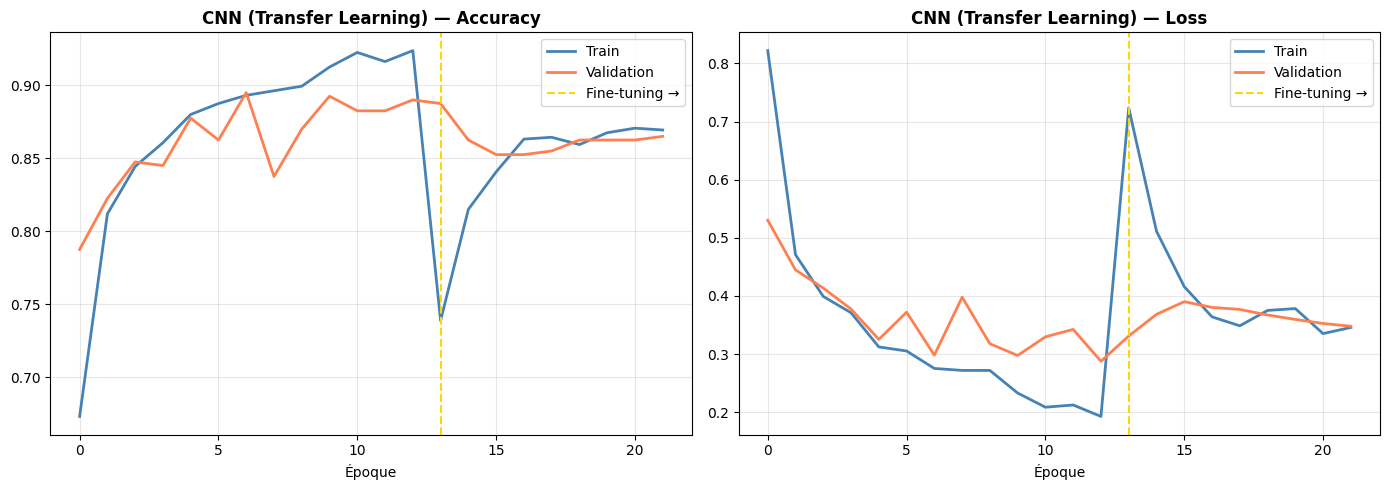


 MobileNetV2 — Accuracy: 0.8875 | Precision: 0.8884 | Recall: 0.8875 | F1: 0.8860

 Rapport détaillé :

                precision    recall  f1-score   support

       Healthy       0.87      1.00      0.93       100
  Early Blight       0.89      0.80      0.84       100
   Late Blight       0.90      0.85      0.88       100
Bacterial Spot       0.89      0.90      0.90       100

      accuracy                           0.89       400
     macro avg       0.89      0.89      0.89       400
  weighted avg       0.89      0.89      0.89       400



In [23]:
# ── 7. Courbes d'apprentissage (Phase 1 + Phase 2 combinées) ────
acc_total  = history1.history['accuracy']  + history2.history['accuracy']
val_total  = history1.history['val_accuracy'] + history2.history['val_accuracy']
loss_total = history1.history['loss']      + history2.history['loss']
vloss_total= history1.history['val_loss']  + history2.history['val_loss']
sep        = len(history1.history['accuracy'])  # séparateur phase 1/2

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (train_h, val_h, title) in zip(axes, [
    (acc_total,  val_total,  'Accuracy'),
    (loss_total, vloss_total, 'Loss')
]):
    ax.plot(train_h, label='Train', color='steelblue', linewidth=2)
    ax.plot(val_h,   label='Validation', color='coral', linewidth=2)
    ax.axvline(x=sep, color='gold', linestyle='--', linewidth=1.5, label='Fine-tuning →')
    ax.set_title(f'CNN (Transfer Learning) — {title}', fontweight='bold')
    ax.set_xlabel('Époque')
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('outputs/08_cnn_training.png', dpi=150, bbox_inches='tight')
plt.show()

# ── 8. Évaluation finale ────────────────────────────────────────
cnn_loss, cnn_acc = cnn_model.evaluate(val_ds, verbose=0)
y_pred_cnn = np.argmax(cnn_model.predict(X_te, verbose=0), axis=1)
y_true_cnn = np.argmax(y_te, axis=1)

cnn_prec = precision_score(y_true_cnn, y_pred_cnn, average='macro', zero_division=0)
cnn_rec  = recall_score(y_true_cnn, y_pred_cnn, average='macro', zero_division=0)
cnn_f1   = f1_score(y_true_cnn, y_pred_cnn, average='macro', zero_division=0)

print(f'\n MobileNetV2 — Accuracy: {cnn_acc:.4f} | Precision: {cnn_prec:.4f} | Recall: {cnn_rec:.4f} | F1: {cnn_f1:.4f}')
print('\n Rapport détaillé :\n')
print(classification_report(y_true_cnn, y_pred_cnn, target_names=CLASS_NAMES))

---

##  ÉTAPE 10 — Étude Comparative Finale ML vs Deep Learning

 Tableau comparatif final :

                     Accuracy  Precision  Recall  F1-Score
Random Forest          0.9000     0.9025  0.9000    0.8994
SVM                    0.9500     0.9504  0.9500    0.9500
KNN                    0.8812     0.8910  0.8812    0.8799
CNN (Deep Learning)    0.8875     0.8884  0.8875    0.8860


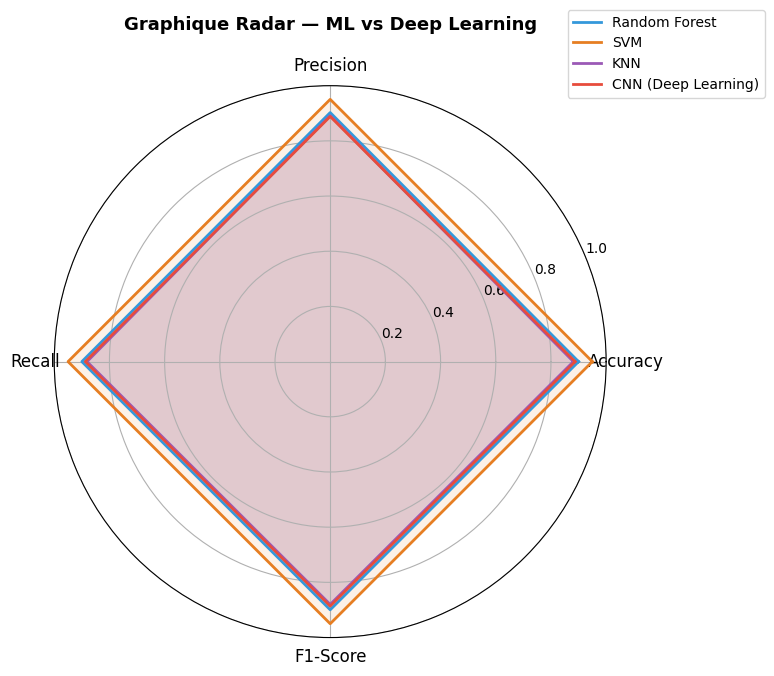

In [24]:
# ─── Tableau comparatif ML vs CNN ────────────────────────────────
all_results = {
    **{name: {'accuracy': results[name]['accuracy'],
              'precision': results[name]['precision'],
              'recall':   results[name]['recall'],
              'f1':       results[name]['f1']} for name in results},
    'CNN (Deep Learning)': {
        'accuracy':  cnn_acc,
        'precision': cnn_prec,
        'recall':    cnn_rec,
        'f1':        cnn_f1
    }
}

df_final = pd.DataFrame(all_results).T
df_final.columns = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
print(' Tableau comparatif final :\n')
print(df_final.round(4).to_string())

# Graphique radar
from matplotlib.patches import FancyBboxPatch

categories = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
N = len(categories)
angles = [n / float(N) * 2 * np.pi for n in range(N)]
angles += angles[:1]

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
radar_colors = ['#3498db', '#e67e22', '#9b59b6', '#e74c3c']

for (name, vals), clr in zip(all_results.items(), radar_colors):
    values = [vals['accuracy'], vals['precision'], vals['recall'], vals['f1']]
    values += values[:1]
    ax.plot(angles, values, linewidth=2, label=name, color=clr)
    ax.fill(angles, values, alpha=0.1, color=clr)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, fontsize=12)
ax.set_ylim(0, 1)
ax.set_title('Graphique Radar — ML vs Deep Learning', fontsize=13, fontweight='bold', pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.15), fontsize=10)
ax.grid(True)

plt.tight_layout()
plt.savefig('outputs/09_radar_comparaison.png', dpi=150, bbox_inches='tight')
plt.show()

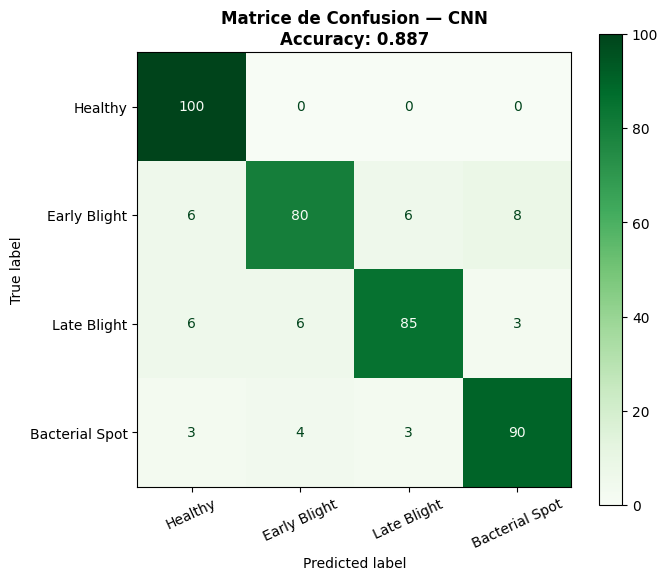


 Rapport CNN :

                precision    recall  f1-score   support

       Healthy       0.87      1.00      0.93       100
  Early Blight       0.89      0.80      0.84       100
   Late Blight       0.90      0.85      0.88       100
Bacterial Spot       0.89      0.90      0.90       100

      accuracy                           0.89       400
     macro avg       0.89      0.89      0.89       400
  weighted avg       0.89      0.89      0.89       400



In [25]:
# ─── Matrice de confusion CNN ─────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 6))
cm_cnn = confusion_matrix(y_true_cnn, y_pred_cnn)
ConfusionMatrixDisplay(cm_cnn, display_labels=CLASS_NAMES).plot(
    ax=ax, colorbar=True, cmap='Greens', xticks_rotation=25
)
ax.set_title(f'Matrice de Confusion — CNN\nAccuracy: {cnn_acc:.3f}', fontweight='bold')
plt.tight_layout()
plt.savefig('outputs/10_confusion_cnn.png', dpi=150, bbox_inches='tight')
plt.show()

print('\n Rapport CNN :\n')
print(classification_report(y_true_cnn, y_pred_cnn, target_names=CLASS_NAMES))

---

##  ÉTAPE 11 — Sauvegarde des modèles et résultats

In [26]:
import pickle

os.makedirs('saved_models', exist_ok=True)

# Sauvegarder les modèles ML
for name, res in results.items():
    fname = f'saved_models/{name.lower().replace(" ","_")}.pkl'
    with open(fname, 'wb') as f:
        pickle.dump(res['model'], f)
    print(f' Sauvegardé : {fname}')

# Sauvegarder le scaler
with open('saved_models/scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)

# Sauvegarder le CNN
cnn_model.save('saved_models/cnn_model.h5')
print(' Sauvegardé : saved_models/cnn_model.h5')

# Sauvegarder les résultats en CSV
df_final.to_csv('outputs/resultats_finaux.csv')
print(' Résultats exportés : outputs/resultats_finaux.csv')

 Sauvegardé : saved_models/random_forest.pkl
 Sauvegardé : saved_models/svm.pkl
 Sauvegardé : saved_models/knn.pkl
 Sauvegardé : saved_models/cnn_model.h5
 Résultats exportés : outputs/resultats_finaux.csv


---

## 📝 Résumé et Conclusions

Ce notebook implémente le pipeline complet suivant :

| Étape | Description |
|-------|-------------|
| Prétraitement | Redimensionnement 128×128, RGB→HSV/Gray, filtre Gaussien, CLAHE |
| Segmentation | Sobel, Canny, Otsu, segmentation couleur HSV |
| Features | Histogrammes RGB+HSV (192 feats), GLCM texture (10), Forme (4) |
| ML | Random Forest, SVM (RBF), KNN — comparés sur Accuracy/Precision/Recall/F1 |
| Deep Learning | CNN 3 blocs Conv+BN+Pool + Data Augmentation |
| Comparaison | Radar chart + tableau comparatif ML vs CNN |

**Classes traitées :**
- `Tomato_healthy` (saine)
- `Tomato_Early_blight` (brûlure précoce)
- `Tomato_Late_blight` (brûlure tardive)
- `Tomato_Bacterial_spot` (tache bactérienne)